In [2]:
import numpy as np
import pandas as pd

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv(r"C:\Users\Pradeep\Downloads\statistics_csv_4.csv")

In [5]:
df.head()

,application_id,Interview Taken on,Status,event_name,Department,Post Name,Offered Salary
0,383422,41760.48668,Hired,Male,Service Department,c8,56553.0
1,907518,41765.33926,Hired,Female,Service Department,c5,22075.0
2,176719,41765.33951,Rejected,Male,Service Department,c5,70069.0
3,429799,41761.68679,Rejected,Female,Operations Department,i4,3207.0
4,253651,41761.68919,Hired,Male,Operations Department,i4,29668.0


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7168 entries, 0 to 7167
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   application_id      7168 non-null   int64  
 1   Interview Taken on  7168 non-null   float64
 2   Status              7168 non-null   str    
 3   event_name          7168 non-null   str    
 4   Department          7164 non-null   str    
 5   Post Name           7168 non-null   str    
 6   Offered Salary      7167 non-null   float64
dtypes: float64(2), int64(1), str(4)
memory usage: 392.1 KB


In [7]:
df.columns = df.columns.str.lower()

In [8]:
df.head(2)

,application_id,interview taken on,status,event_name,department,post name,offered salary
0,383422,41760.48668,Hired,Male,Service Department,c8,56553.0
1,907518,41765.33926,Hired,Female,Service Department,c5,22075.0


In [9]:
df.columns= df.columns.str.replace(' ','_')

In [10]:
df.head(2)

,application_id,interview_taken_on,status,event_name,department,post_name,offered_salary
0,383422,41760.48668,Hired,Male,Service Department,c8,56553.0
1,907518,41765.33926,Hired,Female,Service Department,c5,22075.0


In [11]:
df = df.rename(columns = {'event_name' : 'gender'}) 

In [12]:
df.head(2)

,application_id,interview_taken_on,status,gender,department,post_name,offered_salary
0,383422,41760.48668,Hired,Male,Service Department,c8,56553.0
1,907518,41765.33926,Hired,Female,Service Department,c5,22075.0


In [13]:
print('duplicate rows',df.duplicated().sum())

duplicate rows 0


In [14]:
print(df.duplicated(subset=['application_id']).sum())

27


In [15]:
df = df.drop_duplicates(subset= ['application_id'])

In [16]:
df.info()

<class 'pandas.DataFrame'>
Index: 7141 entries, 0 to 7167
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   application_id      7141 non-null   int64  
 1   interview_taken_on  7141 non-null   float64
 2   status              7141 non-null   str    
 3   gender              7141 non-null   str    
 4   department          7137 non-null   str    
 5   post_name           7141 non-null   str    
 6   offered_salary      7140 non-null   float64
dtypes: float64(2), int64(1), str(4)
memory usage: 446.3 KB


In [17]:
df = df.dropna(subset=['department']).reset_index(drop =True)

In [18]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7137 entries, 0 to 7136
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   application_id      7137 non-null   int64  
 1   interview_taken_on  7137 non-null   float64
 2   status              7137 non-null   str    
 3   gender              7137 non-null   str    
 4   department          7137 non-null   str    
 5   post_name           7137 non-null   str    
 6   offered_salary      7136 non-null   float64
dtypes: float64(2), int64(1), str(4)
memory usage: 390.4 KB


In [19]:
df.loc[df['offered_salary'].isna(), : ]

,application_id,interview_taken_on,status,gender,department,post_name,offered_salary
77,114584,41766.33896,Rejected,Male,Sales Department,i7,NaN


In [20]:
df['offered_salary'] = df.groupby('department')['offered_salary'].transform(lambda x: x.fillna(x.mean()))

In [21]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7137 entries, 0 to 7136
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   application_id      7137 non-null   int64  
 1   interview_taken_on  7137 non-null   float64
 2   status              7137 non-null   str    
 3   gender              7137 non-null   str    
 4   department          7137 non-null   str    
 5   post_name           7137 non-null   str    
 6   offered_salary      7137 non-null   float64
dtypes: float64(2), int64(1), str(4)
memory usage: 390.4 KB


In [22]:
df['interview_taken_on'] = pd.to_datetime(df['interview_taken_on'], unit='D', origin='1899-12-30')

In [23]:
df['interview_taken_on'] = df['interview_taken_on'].dt.floor('D')

In [24]:
df.head(3)

,application_id,interview_taken_on,status,gender,department,post_name,offered_salary
0,383422,2014-05-01,Hired,Male,Service Department,c8,56553.0
1,907518,2014-05-06,Hired,Female,Service Department,c5,22075.0
2,176719,2014-05-06,Rejected,Male,Service Department,c5,70069.0


In [25]:
df['status'].unique()

<StringArray>
['Hired', 'Rejected']
Length: 2, dtype: str

In [26]:
df['gender'].unique()

<StringArray>
['Male', 'Female', '-', 'Don’t want to say']
Length: 4, dtype: str

In [27]:
df['gender'] = df['gender'].str.replace('-','Don’t want to say')

In [28]:
df['gender'].unique()

<StringArray>
['Male', 'Female', 'Don’t want to say']
Length: 3, dtype: str

In [29]:
df['department'].unique()

<StringArray>
[       'Service Department',     'Operations Department',
          'Sales Department',        'Finance Department',
     'Production Department',       'Purchase Department',
      'Marketing Department',        'General Management',
 'Human Resource Department']
Length: 9, dtype: str

In [30]:
df['department'] = df['department'].str.replace('Department', '', case=False).str.strip()
# case = case sensitivity

In [31]:
df['department'].unique()

<StringArray>
[           'Service',         'Operations',              'Sales',
            'Finance',         'Production',           'Purchase',
          'Marketing', 'General Management',     'Human Resource']
Length: 9, dtype: str

In [32]:
df['post_name'].unique()

<StringArray>
[  'c8',   'c5',   'i4',    '-',   'i7',  'n10',   'b9',   'i5',   'i1',
   'i6',   'm6',   'm7', 'c-10',   'c9',   'n9',   'n6']
Length: 16, dtype: str

In [33]:
df['post_name'] = df['post_name'].str.replace('-','')

In [34]:
df['post_name'].unique()

<StringArray>
[ 'c8',  'c5',  'i4',    '',  'i7', 'n10',  'b9',  'i5',  'i1',  'i6',  'm6',
  'm7', 'c10',  'c9',  'n9',  'n6']
Length: 16, dtype: str

In [35]:
df['post_name'] = df['post_name'].replace('','Not Mentioned')

In [36]:
df['post_name'].unique()

<StringArray>
[           'c8',            'c5',            'i4', 'Not Mentioned',
            'i7',           'n10',            'b9',            'i5',
            'i1',            'i6',            'm6',            'm7',
           'c10',            'c9',            'n9',            'n6']
Length: 16, dtype: str

In [37]:
df

,application_id,interview_taken_on,status,gender,department,post_name,offered_salary
0,383422,2014-05-01,Hired,Male,Service,c8,56553.0
1,907518,2014-05-06,Hired,Female,Service,c5,22075.0
2,176719,2014-05-06,Rejected,Male,Service,c5,70069.0
3,429799,2014-05-02,Rejected,Female,Operations,i4,3207.0
4,253651,2014-05-02,Hired,Male,Operations,i4,29668.0
...,...,...,...,...,...,...,...
7132,493131,2014-08-28,Hired,Male,Service,c9,49282.0
7133,214261,2014-08-31,Hired,Female,Service,c5,57742.0
7134,932441,2014-08-31,Hired,Male,Service,c5,69932.0
7135,39010,2014-08-31,Rejected,Male,Service,c5,14489.0


In [38]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7137 entries, 0 to 7136
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   application_id      7137 non-null   int64         
 1   interview_taken_on  7137 non-null   datetime64[ns]
 2   status              7137 non-null   str           
 3   gender              7137 non-null   str           
 4   department          7137 non-null   str           
 5   post_name           7137 non-null   str           
 6   offered_salary      7137 non-null   float64       
dtypes: datetime64[ns](1), float64(1), int64(1), str(4)
memory usage: 390.4 KB


In [39]:
df.describe(include ='all')

,application_id,interview_taken_on,status,gender,department,post_name,offered_salary
count,7137.000000,7137,7137,7137,7137,7137,7137.000000
unique,NaN,NaN,2,3,9,16,NaN
top,NaN,NaN,Hired,Male,Operations,c9,NaN
freq,NaN,NaN,4679,4069,2760,1783,NaN
mean,508208.095698,2014-07-02 08:29:03.253467648,NaN,NaN,NaN,NaN,50015.006550
min,12073.000000,2014-05-01 00:00:00,NaN,NaN,NaN,NaN,100.000000
25%,261521.000000,2014-06-02 00:00:00,NaN,NaN,NaN,NaN,25583.000000
50%,507460.000000,2014-07-04 00:00:00,NaN,NaN,NaN,NaN,49658.000000
75%,756858.000000,2014-08-01 00:00:00,NaN,NaN,NaN,NaN,74463.000000
max,999936.000000,2014-08-31 00:00:00,NaN,NaN,NaN,NaN,400000.000000


In [40]:
q1 = df['offered_salary'].quantile(0.25)
q3 = df['offered_salary'].quantile(0.75)
IQR = q3 - q1

In [41]:
lower_bound = q1 - 1.5*IQR
upper_bound = q3 + 1.5*IQR

In [42]:
outliers = df[(df['offered_salary']<lower_bound) | (df['offered_salary']>upper_bound)]

In [43]:
outliers.shape

(3, 7)

In [44]:
df = df[(df['offered_salary'] >= lower_bound) & (df['offered_salary'] <= upper_bound)].reset_index(drop=True)

In [45]:
df.describe()

,application_id,interview_taken_on,offered_salary
count,7134.000000,7134,7134.000000
mean,508096.781890,2014-07-02 08:40:10.092514816,49909.882499
min,12073.000000,2014-05-01 00:00:00,100.000000
25%,261260.750000,2014-06-02 00:00:00,25582.250000
50%,507291.500000,2014-07-04 00:00:00,49633.500000
75%,756613.500000,2014-08-01 00:00:00,74418.500000
max,999936.000000,2014-08-31 00:00:00,99967.000000
std,285147.681025,NaN,28349.429586


In [46]:
print("=== NUMERICAL SUMMARY ===")
print(df[['offered_salary']].describe().T)

=== NUMERICAL SUMMARY ===
                 count          mean           std    min       25%      50%  \
offered_salary  7134.0  49909.882499  28349.429586  100.0  25582.25  49633.5   

                    75%      max  
offered_salary  74418.5  99967.0  


In [47]:
print("\n=== HIRING CONVERSION BY DEPARTMENT ===\n")
dept_conversion = df.groupby('department')['status'].value_counts( normalize = True).unstack() * 100
print(dept_conversion.round(2))


=== HIRING CONVERSION BY DEPARTMENT ===

status              Hired  Rejected
department                         
Finance             61.32     38.68
General Management  66.07     33.93
Human Resource      71.88     28.12
Marketing           62.15     37.85
Operations          66.52     33.48
Production          64.81     35.19
Purchase            69.28     30.72
Sales               64.92     35.08
Service             64.77     35.23


In [48]:
print("\n=== SALARY BREAKDOWN BY DEPARTMENT ===\n")
salary_by_dept = df.groupby('department')['offered_salary'].agg(['count', 'mean', 'median', 'std']).round(2)
print(salary_by_dept)


=== SALARY BREAKDOWN BY DEPARTMENT ===

                    count      mean   median       std
department                                            
Finance               287  49759.30  51497.0  27583.67
General Management    168  55327.04  58709.5  27696.54
Human Resource         96  49448.64  52374.0  29919.49
Marketing             325  48489.94  45843.0  29392.53
Operations           2760  49142.23  47804.5  28442.38
Production            378  49434.38  46704.5  28644.07
Purchase              332  52669.64  55193.0  27992.69
Sales                 744  49403.75  48844.5  27927.44
Service              2044  50593.68  50430.0  28254.20


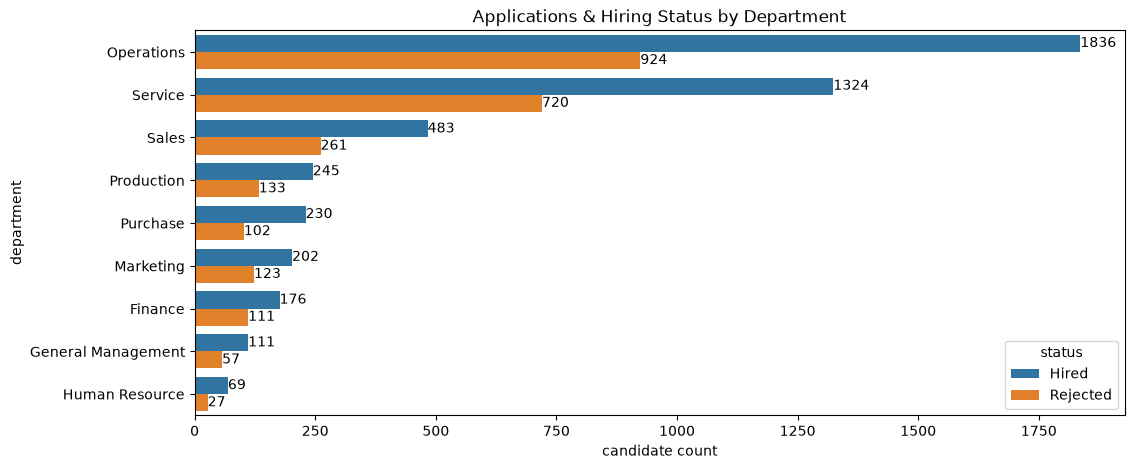

In [52]:
plt.figure(figsize=(12,5))

dept_order = df['department'].value_counts().index
ax = sns.countplot(data=df,y='department',hue = 'status',order = dept_order)
plt.xlabel('candidate count')
plt.ylabel('department')
plt.legend(title = 'status')
plt.title('Applications & Hiring Status by Department')

for bars in ax.containers:
    ax.bar_label(bars)

plt.show()

C:\Users\Pradeep\AppData\Local\Temp\ipykernel_30036\4075711686.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='offered_salary',y = 'department',data = df,order = dept_order,palette='Blues')


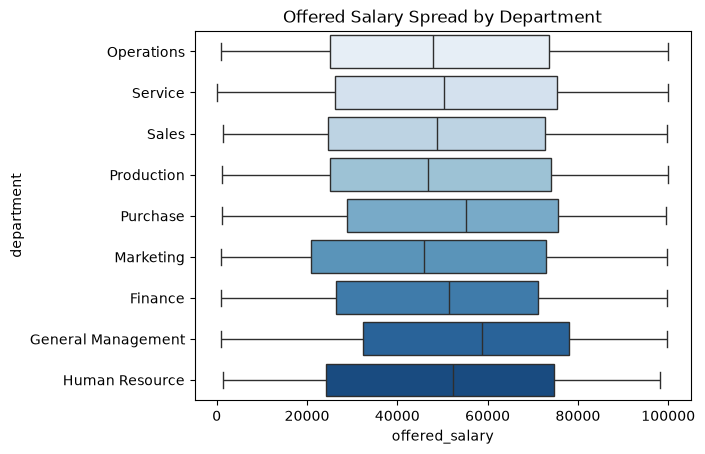

In [90]:
dept_order = df['department'].value_counts().index
sns.boxplot(x='offered_salary',y = 'department',data = df,order = dept_order,palette='Blues')
plt.xlabel('offered_salary')
plt.ylabel('department')
plt.title('Offered Salary Spread by Department')

plt.show()

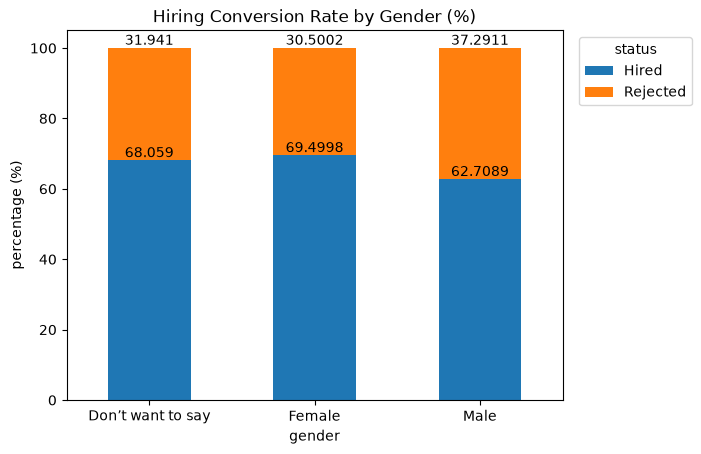

In [61]:
gender_hire = pd.crosstab(df['gender'], df['status'], normalize='index') * 100
ay = gender_hire.plot(kind = 'bar',stacked=True,rot=0)

plt.xlabel('gender')
plt.ylabel('percentage (%)')
plt.legend(title = 'status',bbox_to_anchor=(1.02, 1))
plt.title('Hiring Conversion Rate by Gender (%)')

for bars in ay.containers:
    ay.bar_label(bars)

plt.show()

In [126]:
# what percentage of all hired & rejected candidates were female vs. male.
pd.crosstab(df['gender'], df['status'], normalize='columns') * 100


status,Hired,Rejected
gender,,
Don’t want to say,5.923867,5.288853
Female,39.520958,32.994304
Male,54.555175,61.716843


<function matplotlib.pyplot.show(close=None, block=None)>

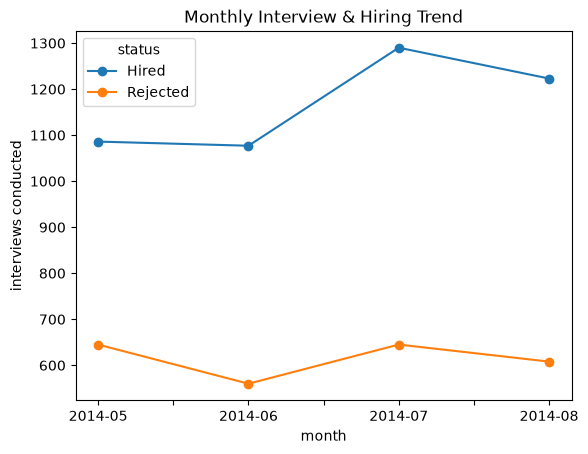

In [63]:
df['interview_month_year'] = df['interview_taken_on'].dt.strftime('%Y-%m')
monthly_trend = df[['interview_month_year', 'status']].value_counts().unstack()
monthly_trend.plot(kind='line',marker='o')

plt.xlabel('month')
plt.ylabel('interviews conducted')
plt.title('Monthly Interview & Hiring Trend')

plt.show

In [128]:
df.drop('interview_month_year',axis=1,inplace=True)

In [131]:
%pip install pymysql sqlalchemy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\Pradeep\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [133]:
from sqlalchemy import create_engine

# MySQL connection
username = "root"
password = "9829829628Kk"
host = "localhost"
port = "3306"
database = "hiring_data"

engine = create_engine(f"mysql+pymysql://{username}:{password}@{host}:{port}/{database}")

# Write DataFrame to MySQL
table_name = "candidates"   # choose any table name
df.to_sql(table_name, engine, if_exists="replace", index=False)


7134